# Geometría computacional · Primitivas y polígonos

Las piezas básicas de la geometría computacional: el producto vectorial y la orientación de tres puntos, la fórmula del cordón para el área (con su signo), el perímetro y el centroide, la convexidad, el punto en polígono (por rayos y por número de vueltas), la intersección de segmentos con todos sus casos degenerados, la distancia de un punto a un segmento, el teorema de Pick, la triangulación por orejas y las transformaciones con matrices. Siempre que se puede se trabaja con enteros y `Fraction`, así que las comparaciones son exactas y no hacen falta tolerancias.

In [1]:
import math
import random
from fractions import Fraction
from itertools import combinations, pairwise

import matplotlib.pyplot as plt
import numpy as np

plt.rcParams.update({"figure.figsize": (6, 3.5), "figure.dpi": 80})

## 1. Producto vectorial y orientación

Escribir `cruz(o, a, b)`, el producto vectorial $(a - o) \times (b - o) = (a_x - o_x)(b_y - o_y) - (a_y - o_y)(b_x - o_x)$, y `orientacion(a, b, c)`, que devuelva `1` si el giro $a \to b \to c$ es antihorario, `-1` si es horario y `0` si los puntos están alineados. Comprobar que la orientación no cambia al rotar el orden de los puntos, que cambia de signo al intercambiar dos, y que vale 0 justo cuando las pendientes (como `Fraction`) coinciden.

In [2]:
def cruz(o, a, b):
    return (a[0] - o[0]) * (b[1] - o[1]) - (a[1] - o[1]) * (b[0] - o[0])


def orientacion(a, b, c):
    v = cruz(a, b, c)
    return (v > 0) - (v < 0)


nombres = {1: "antihorario", -1: "horario", 0: "alineados"}
for trio in [((0, 0), (4, 0), (2, 3)), ((0, 0), (2, 3), (4, 0)), ((1, 1), (3, 5), (5, 9))]:
    print(trio, "→", nombres[orientacion(*trio)])

def alineados(a, b, c):
    if a == b or a == c:
        return True
    if b[0] == a[0] or c[0] == a[0]:
        return b[0] == a[0] == c[0]
    return Fraction(b[1] - a[1], b[0] - a[0]) == Fraction(c[1] - a[1], c[0] - a[0])


rng = random.Random(1)
for _ in range(2000):
    a, b, c = [(rng.randint(-5, 5), rng.randint(-5, 5)) for _ in range(3)]
    s = orientacion(a, b, c)
    assert s == orientacion(b, c, a) == orientacion(c, a, b) == -orientacion(b, a, c)
    assert (s == 0) == alineados(a, b, c)

((0, 0), (4, 0), (2, 3)) → antihorario
((0, 0), (2, 3), (4, 0)) → horario
((1, 1), (3, 5), (5, 9)) → alineados


## 2. Área con la fórmula del cordón

El área con signo de un polígono de vértices $p_0, \dots, p_{n-1}$ es $A = \frac{1}{2}\sum_i (x_i y_{i+1} - x_{i+1} y_i)$: positiva si los vértices van en sentido antihorario y negativa si van en sentido horario. Escribir `area_con_signo(poligono)` devolviendo una `Fraction`, aplicarla a un rectángulo, a un polígono en forma de L y al mismo L recorrido al revés, y comprobarla abanicando triángulos desde un punto cualquiera (aunque esté fuera del polígono, las áreas con signo se compensan).

In [3]:
def area_con_signo(poligono):
    n = len(poligono)
    doble = sum(poligono[i][0] * poligono[(i + 1) % n][1] - poligono[(i + 1) % n][0] * poligono[i][1] for i in range(n))
    return Fraction(doble, 2)


def area_por_abanico(poligono, o):
    n = len(poligono)
    return sum(Fraction(cruz(o, poligono[i], poligono[(i + 1) % n]), 2) for i in range(n))


rectangulo = [(0, 0), (6, 0), (6, 3), (0, 3)]
ele = [(0, 0), (4, 0), (4, 1), (1, 1), (1, 3), (0, 3)]
for nombre, p in [("rectángulo", rectangulo), ("L", ele), ("L al revés", ele[::-1])]:
    print(f"{nombre:<12} área con signo = {area_con_signo(p)}")

assert area_con_signo(rectangulo) == 18 and area_con_signo(ele) == 6 and area_con_signo(ele[::-1]) == -6
for o in [(0, 0), (2, 2), (-7, 11), (100, -3)]:
    assert area_por_abanico(ele, o) == area_con_signo(ele)

rectángulo   área con signo = 18
L            área con signo = 6
L al revés   área con signo = -6


## 3. Perímetro y centroide

Escribir `perimetro(poligono)` y `centroide(poligono)`. El centroide (centro de masas de la lámina, no la media de los vértices) es $C_x = \frac{1}{6A}\sum_i (x_i + x_{i+1})(x_i y_{i+1} - x_{i+1} y_i)$ y análogo para $C_y$. Calcularlo para la L del ejercicio anterior y comprobarlo descomponiéndola en dos rectángulos y haciendo la media de sus centros ponderada por sus áreas. Mostrar también que la media de los vértices da otro punto.

In [4]:
def perimetro(poligono):
    return sum(math.dist(p, q) for p, q in pairwise(poligono + poligono[:1]))


def centroide(poligono):
    n, a = len(poligono), area_con_signo(poligono)
    cx = cy = Fraction(0)
    for i in range(n):
        (x0, y0), (x1, y1) = poligono[i], poligono[(i + 1) % n]
        c = x0 * y1 - x1 * y0
        cx += (x0 + x1) * c
        cy += (y0 + y1) * c
    return cx / (6 * a), cy / (6 * a)


print("Perímetro de la L:", perimetro(ele))
print("Centroide de la L:", *centroide(ele))
print("Media de los vértices:", *(Fraction(sum(c), len(ele)) for c in zip(*ele)))

# L = rectángulo [0,4]×[0,1] (área 4) + rectángulo [0,1]×[1,3] (área 2)
piezas = [(4, (Fraction(2), Fraction(1, 2))), (2, (Fraction(1, 2), Fraction(2)))]
esperado = tuple(sum(a * c[k] for a, c in piezas) / 6 for k in range(2))
assert centroide(ele) == esperado == centroide(ele[::-1])
assert perimetro(ele) == 14

Perímetro de la L: 14.0
Centroide de la L: 3/2 1
Media de los vértices: 5/3 4/3


## 4. ¿Es convexo?

Un polígono simple es convexo si todos los giros entre aristas consecutivas tienen la misma orientación (los vértices alineados no cuentan). Escribir `es_convexo(poligono)` y probarlo con un hexágono, con la L, con un cuadrado con un vértice repetido en medio de un lado y con una estrella. Comprobarlo con otra definición: un polígono es convexo si, para cada arista, todos los demás vértices quedan del mismo lado.

In [5]:
def es_convexo(poligono):
    n = len(poligono)
    giros = {orientacion(poligono[i], poligono[(i + 1) % n], poligono[(i + 2) % n]) for i in range(n)} - {0}
    return len(giros) <= 1


def es_convexo_por_aristas(poligono):
    n = len(poligono)
    for i in range(n):
        a, b = poligono[i], poligono[(i + 1) % n]
        lados = {orientacion(a, b, p) for p in poligono} - {0}
        if len(lados) > 1:
            return False
    return True


hexagono = [(2, 0), (4, 1), (4, 3), (2, 4), (0, 3), (0, 1)]
cuadrado_con_punto = [(0, 0), (2, 0), (4, 0), (4, 4), (0, 4)]
estrella = [(0, 3), (2, 2), (3, 0), (4, 2), (6, 3), (4, 4), (3, 6), (2, 4)]
for nombre, p in [("hexágono", hexagono), ("L", ele), ("cuadrado con punto", cuadrado_con_punto), ("estrella", estrella)]:
    print(f"{nombre:<20} convexo: {es_convexo(p)}")
    assert es_convexo(p) == es_convexo_por_aristas(p)

hexágono             convexo: True
L                    convexo: False
cuadrado con punto   convexo: True
estrella             convexo: False


## 5. Punto en polígono por rayos

Escribir `dentro_por_rayo(punto, poligono)`: se lanza un rayo horizontal hacia la derecha y se cuentan las aristas que cruza; si el número es impar, el punto está dentro. Para no contar dos veces un vértice, cada arista se toma como semiabierta ($y_i \le y < y_{i+1}$ o al revés), y los puntos del borde se detectan aparte y devuelven `"borde"`. Comprobarlo en la L con todos los puntos de una rejilla, contra la descomposición en rectángulos.

In [6]:
def en_segmento(p, a, b):
    return cruz(a, b, p) == 0 and min(a[0], b[0]) <= p[0] <= max(a[0], b[0]) and min(a[1], b[1]) <= p[1] <= max(a[1], b[1])


def dentro_por_rayo(punto, poligono):
    x, y = punto
    n, dentro = len(poligono), False
    for i in range(n):
        a, b = poligono[i], poligono[(i + 1) % n]
        if en_segmento(punto, a, b):
            return "borde"
        if (a[1] <= y) != (b[1] <= y):
            # Corte del rayo con la arista, comparado sin dividir: x_corte > x
            corte = (b[0] - a[0]) * (y - a[1]) - (x - a[0]) * (b[1] - a[1])
            if (corte > 0) == (b[1] > a[1]):
                dentro = not dentro
    return dentro


def dentro_de_ele(x, y):
    estricto = (0 < x < 4 and 0 < y < 1) or (0 < x < 1 and 0 < y < 3) or (0 < x < 1 and y == 1)
    borde = (x in (0,) and 0 <= y <= 3) or (y == 0 and 0 <= x <= 4) or (x == 4 and 0 <= y <= 1) or \
            (y == 1 and 1 <= x <= 4) or (x == 1 and 1 <= y <= 3) or (y == 3 and 0 <= x <= 1)
    return "borde" if borde else estricto


fracciones = [Fraction(k, 2) for k in range(-2, 11)]
for x in fracciones:
    for y in fracciones:
        assert dentro_por_rayo((x, y), ele) == dentro_de_ele(x, y), (x, y)

filas = []
for y in range(3, -1, -1):
    fila = ""
    for x in range(5):
        r = dentro_por_rayo((x + Fraction(1, 2), y + Fraction(1, 2)), ele)
        fila += "█" if r is True else "·"
    filas.append(fila)
print("\n".join(filas))

·····
█····
█····
████·


## 6. Número de vueltas

El número de vueltas (*winding number*) cuenta cuántas veces el contorno rodea al punto, con signo. Escribir `numero_de_vueltas(punto, poligono)` sumando $+1$ por cada arista que cruza la horizontal del punto subiendo con el punto a su izquierda y $-1$ por cada una que la cruza bajando con el punto a su derecha. En un polígono simple coincide con la paridad del rayo; en uno que se corta a sí mismo, como el pentagrama, el centro tiene número de vueltas 2 (está dentro) aunque el rayo diga «fuera». Comprobar la equivalencia en polígonos simples y mostrar el pentagrama por colores.

Centro del pentagrama: vueltas = 2 | rayo: False


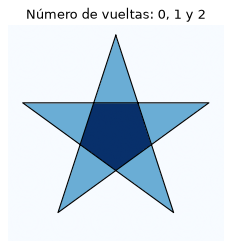

In [7]:
def numero_de_vueltas(punto, poligono):
    vueltas, n = 0, len(poligono)
    for i in range(n):
        a, b = poligono[i], poligono[(i + 1) % n]
        if a[1] <= punto[1] < b[1] and cruz(a, b, punto) > 0:
            vueltas += 1
        elif b[1] <= punto[1] < a[1] and cruz(a, b, punto) < 0:
            vueltas -= 1
    return vueltas


rng = random.Random(6)
for p in [ele, estrella, hexagono, ele[::-1]]:
    for _ in range(500):
        q = (Fraction(rng.randint(-20, 140), 20), Fraction(rng.randint(-20, 140), 20))
        r = dentro_por_rayo(q, p)
        if r != "borde":
            assert r == (numero_de_vueltas(q, p) != 0)

pentagrama = [(round(100 * math.cos(math.pi / 2 + 4 * math.pi * k / 5)), round(100 * math.sin(math.pi / 2 + 4 * math.pi * k / 5)))
              for k in range(5)]
print("Centro del pentagrama: vueltas =", numero_de_vueltas((0, 0), pentagrama), "| rayo:", dentro_por_rayo((0, 0), pentagrama))
assert numero_de_vueltas((0, 0), pentagrama) == 2 and dentro_por_rayo((0, 0), pentagrama) is False

xs = np.linspace(-110, 110, 221)
mapa = np.array([[numero_de_vueltas((x, y), pentagrama) for x in xs] for y in xs])
fig, ax = plt.subplots(figsize=(3.5, 3.5))
ax.imshow(mapa, origin="lower", extent=(-110, 110, -110, 110), cmap="Blues")
ax.plot(*zip(*(pentagrama + pentagrama[:1])), color="black", lw=1)
ax.set_title("Número de vueltas: 0, 1 y 2")
ax.set_axis_off()
plt.show()

## 7. Intersección de segmentos

Escribir `se_cortan(p1, p2, q1, q2)` con las cuatro orientaciones: los segmentos se cortan si cada uno separa los extremos del otro, o si algún extremo está alineado y dentro del otro segmento (casos de extremos que se tocan, segmentos colineales solapados o segmentos de longitud cero). Escribir también `punto_de_corte`, que devuelva el punto exacto con `Fraction`, un segmento si se solapan o `None`. Comprobar `se_cortan` contra `punto_de_corte` con miles de segmentos aleatorios de coordenadas pequeñas (para que abunden los casos degenerados).

In [8]:
def se_cortan(p1, p2, q1, q2):
    o1, o2 = orientacion(p1, p2, q1), orientacion(p1, p2, q2)
    o3, o4 = orientacion(q1, q2, p1), orientacion(q1, q2, p2)
    if o1 != o2 and o3 != o4 and 0 not in (o1, o2, o3, o4):
        return True
    return (o1 == 0 and en_segmento(q1, p1, p2)) or (o2 == 0 and en_segmento(q2, p1, p2)) or \
           (o3 == 0 and en_segmento(p1, q1, q2)) or (o4 == 0 and en_segmento(p2, q1, q2))


def punto_de_corte(p1, p2, q1, q2):
    """Resuelve p1 + t(p2 - p1) = q1 + u(q2 - q1) con t, u en [0, 1]."""
    r = (p2[0] - p1[0], p2[1] - p1[1])
    s = (q2[0] - q1[0], q2[1] - q1[1])
    den = r[0] * s[1] - r[1] * s[0]
    dq = (q1[0] - p1[0], q1[1] - p1[1])
    if den != 0:
        t = Fraction(dq[0] * s[1] - dq[1] * s[0], den)
        u = Fraction(dq[0] * r[1] - dq[1] * r[0], den)
        return (p1[0] + t * r[0], p1[1] + t * r[1]) if 0 <= t <= 1 and 0 <= u <= 1 else None
    # Paralelos (o degenerados): solo hay corte si están en la misma recta
    if cruz(p1, p2, q1) != 0 or cruz(p1, p2, q2) != 0 or cruz(q1, q2, p1) != 0:
        return None
    clave = (lambda p: (p[0], p[1]))
    a, b = sorted([p1, p2], key=clave), sorted([q1, q2], key=clave)
    inicio, fin = max(a[0], b[0], key=clave), min(a[1], b[1], key=clave)
    if clave(inicio) > clave(fin):
        return None
    return inicio if inicio == fin else (inicio, fin)


casos = {
    "se cruzan": ((0, 0), (4, 4), (0, 4), (4, 0)),
    "en T": ((0, 0), (4, 0), (2, 0), (2, 3)),
    "extremo común": ((0, 0), (2, 2), (2, 2), (5, 0)),
    "colineales solapados": ((0, 0), (4, 0), (2, 0), (6, 0)),
    "colineales separados": ((0, 0), (1, 0), (2, 0), (3, 0)),
    "paralelos": ((0, 0), (4, 0), (0, 1), (4, 1)),
    "corte fraccionario": ((0, 0), (3, 1), (0, 1), (2, 0)),
}
def como_texto(x):
    return f"({', '.join(map(como_texto, x))})" if isinstance(x, tuple) else str(x)


for nombre, seg in casos.items():
    print(f"{nombre:<22} {se_cortan(*seg)!s:<6} {como_texto(punto_de_corte(*seg))}")

rng = random.Random(7)
for _ in range(20_000):
    puntos = [(rng.randint(0, 3), rng.randint(0, 3)) for _ in range(4)]
    assert se_cortan(*puntos) == (punto_de_corte(*puntos) is not None), puntos

se cruzan              True   (2, 2)
en T                   True   (2, 0)
extremo común          True   (2, 2)
colineales solapados   True   ((2, 0), (4, 0))
colineales separados   False  None
paralelos              False  None
corte fraccionario     True   (6/5, 2/5)


## 8. Distancia de un punto a un segmento

Escribir `distancia_a_segmento(p, a, b)`: se proyecta $p$ sobre la recta $ab$ con $t = \frac{(p - a)\cdot(b - a)}{|b - a|^2}$, se recorta $t$ a $[0, 1]$ y se mide la distancia al punto obtenido. Devolver el cuadrado de la distancia como `Fraction` (exacto) y la distancia como `float`. Comprobarla con 1001 puntos repartidos a lo largo del segmento y mostrar en una figura las curvas de nivel de la distancia, que son un «estadio».

(4, 6) → d² = 49/5, d ≈ 3.1305
(0, 0) → d² = 2, d ≈ 1.4142
(10, 2) → d² = 13, d ≈ 3.6056
(3, 2) → d² = 0, d ≈ 0.0000


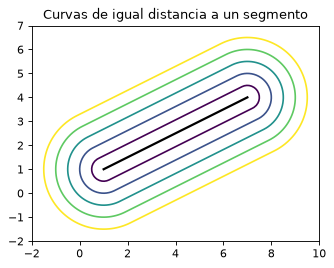

In [9]:
def distancia2_a_segmento(p, a, b):
    d = (b[0] - a[0], b[1] - a[1])
    largo2 = d[0] ** 2 + d[1] ** 2
    t = Fraction(0) if largo2 == 0 else Fraction((p[0] - a[0]) * d[0] + (p[1] - a[1]) * d[1], largo2)
    t = min(max(t, Fraction(0)), Fraction(1))
    cx, cy = a[0] + t * d[0], a[1] + t * d[1]
    return (p[0] - cx) ** 2 + (p[1] - cy) ** 2


def distancia_a_segmento(p, a, b):
    return math.sqrt(distancia2_a_segmento(p, a, b))


a, b = (1, 1), (7, 4)
for p in [(4, 6), (0, 0), (10, 2), (3, 2)]:
    print(f"{p} → d² = {distancia2_a_segmento(p, a, b)}, d ≈ {distancia_a_segmento(p, a, b):.4f}")

rng = random.Random(8)
ts = np.linspace(0, 1, 1001)
for _ in range(300):
    a, b, p = [(rng.randint(-9, 9), rng.randint(-9, 9)) for _ in range(3)]
    muestras = np.hypot(a[0] + ts * (b[0] - a[0]) - p[0], a[1] + ts * (b[1] - a[1]) - p[1]).min()
    assert distancia_a_segmento(p, a, b) <= muestras + 1e-12
    assert muestras - distancia_a_segmento(p, a, b) < 0.03

a, b = (1, 1), (7, 4)
xs, ys = np.meshgrid(np.linspace(-2, 10, 120), np.linspace(-2, 7, 90))
t = np.clip(((xs - a[0]) * (b[0] - a[0]) + (ys - a[1]) * (b[1] - a[1])) / 45, 0, 1)
dist = np.hypot(xs - a[0] - t * (b[0] - a[0]), ys - a[1] - t * (b[1] - a[1]))
fig, ax = plt.subplots()
ax.contour(xs, ys, dist, levels=[0.5, 1, 1.5, 2, 2.5], cmap="viridis")
ax.plot(*zip(a, b), color="black", lw=2)
ax.set_aspect("equal")
ax.set_title("Curvas de igual distancia a un segmento")
plt.show()

## 9. Teorema de Pick

Para un polígono simple con vértices en puntos de coordenadas enteras, $A = I + \frac{B}{2} - 1$, donde $I$ son los puntos enteros del interior y $B$ los del borde. Calcular $B$ sumando $\gcd(|\Delta x|, |\Delta y|)$ en cada arista, despejar $I$ y comprobar las dos cifras contando por fuerza bruta todos los puntos de la caja que contiene al polígono (con `dentro_por_rayo`).

In [10]:
def puntos_en_borde(poligono):
    return sum(math.gcd(abs(q[0] - p[0]), abs(q[1] - p[1])) for p, q in pairwise(poligono + poligono[:1]))


def pick(poligono):
    area = abs(area_con_signo(poligono))
    b = puntos_en_borde(poligono)
    return area, b, area - Fraction(b, 2) + 1


def contar_a_mano(poligono):
    xs, ys = zip(*poligono)
    conteo = {True: 0, False: 0, "borde": 0}
    for x in range(min(xs), max(xs) + 1):
        for y in range(min(ys), max(ys) + 1):
            conteo[dentro_por_rayo((x, y), poligono)] += 1
    return conteo["borde"], conteo[True]


print(f"{'polígono':<10} {'área':>6} {'B':>4} {'I':>4}")
for nombre, p in [("L", ele), ("hexágono", hexagono), ("estrella", estrella), ("triángulo", [(0, 0), (7, 2), (3, 9)])]:
    area, b, i = pick(p)
    print(f"{nombre:<10} {str(area):>6} {b:>4} {str(i):>4}")
    assert (b, i) == contar_a_mano(p)

polígono     área    B    I
L               6   14    0
hexágono       12    8    9
estrella       12    8    9
triángulo    57/2    5   27


## 10. Triangulación por orejas

Una oreja de un polígono simple es un vértice convexo $v_i$ tal que el triángulo $v_{i-1} v_i v_{i+1}$ no contiene ningún otro vértice. Todo polígono simple con más de tres vértices tiene al menos dos orejas, así que se puede triangular cortando orejas una a una. Escribir `triangular(poligono)` (en sentido antihorario) y comprobar que da $n - 2$ triángulos, todos con orientación positiva, y que sus áreas suman el área del polígono. Dibujar la triangulación de un polígono con forma de herradura.

L                    4 triángulos, área 6
estrella             6 triángulos, área 12
herradura            6 triángulos, área 24
herradura al revés   6 triángulos, área 24


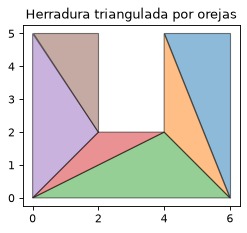

In [11]:
def en_triangulo(p, a, b, c):
    return orientacion(a, b, p) >= 0 and orientacion(b, c, p) >= 0 and orientacion(c, a, p) >= 0


def triangular(poligono):
    if area_con_signo(poligono) < 0:
        poligono = poligono[::-1]
    restantes, triangulos = list(poligono), []
    while len(restantes) > 3:
        n = len(restantes)
        for i in range(n):
            a, b, c = restantes[i - 1], restantes[i], restantes[(i + 1) % n]
            if orientacion(a, b, c) <= 0:
                continue
            if any(en_triangulo(p, a, b, c) for p in restantes if p not in (a, b, c)):
                continue
            triangulos.append((a, b, c))
            del restantes[i]
            break
        else:
            raise ValueError("no hay orejas: ¿el polígono es simple?")
    return triangulos + [tuple(restantes)]


herradura = [(0, 0), (6, 0), (6, 5), (4, 5), (4, 2), (2, 2), (2, 5), (0, 5)]
for nombre, p in [("L", ele), ("estrella", estrella), ("herradura", herradura), ("herradura al revés", herradura[::-1])]:
    tri = triangular(p)
    assert len(tri) == len(p) - 2
    assert all(area_con_signo(list(t)) > 0 for t in tri)
    assert sum(area_con_signo(list(t)) for t in tri) == abs(area_con_signo(p))
    print(f"{nombre:<20} {len(tri)} triángulos, área {abs(area_con_signo(p))}")

fig, ax = plt.subplots(figsize=(3.5, 3))
for t in triangular(herradura):
    ax.fill(*zip(*t), alpha=0.5, edgecolor="black")
ax.set_aspect("equal")
ax.set_title("Herradura triangulada por orejas")
plt.show()

## 11. Rotaciones y transformaciones con matrices

Representar los puntos en coordenadas homogéneas $(x, y, 1)$ para que traslaciones, giros y escalados sean matrices $3 \times 3$ y se compongan multiplicándolas. Escribir `traslacion`, `giro` y `escala`, y construir la matriz que gira la L 90° alrededor de su centroide. Comprobar que el giro exacto de 90° con enteros, $(x, y) \mapsto (-y, x)$, coincide con la matriz, que el giro conserva el área y el centroide, que un escalado multiplica el área por su determinante y que una simetría cambia su signo.

[[ 2.5 -0.5]
 [ 2.5  3.5]
 [ 1.5  3.5]
 [ 1.5  0.5]
 [-0.5  0.5]
 [-0.5 -0.5]]
escala 2×3   det = +6.00, área = +36.00
simetría     det = -1.00, área = -6.00
giro∘escala  det = +0.50, área = +3.00


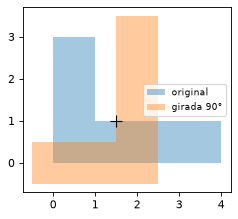

In [12]:
def traslacion(dx, dy):
    return np.array([[1, 0, dx], [0, 1, dy], [0, 0, 1]], dtype=float)


def giro(angulo):
    c, s = math.cos(angulo), math.sin(angulo)
    return np.array([[c, -s, 0], [s, c, 0], [0, 0, 1]])


def escala(sx, sy):
    return np.diag([sx, sy, 1.0])


def aplicar(matriz, poligono):
    homogeneos = np.column_stack([np.array(poligono, dtype=float), np.ones(len(poligono))])
    return (homogeneos @ matriz.T)[:, :2]


def area_float(puntos):
    x, y = puntos[:, 0], puntos[:, 1]
    return 0.5 * np.sum(x * np.roll(y, -1) - np.roll(x, -1) * y)


cx, cy = (float(c) for c in centroide(ele))
girar_en_centroide = traslacion(cx, cy) @ giro(math.pi / 2) @ traslacion(-cx, -cy)
girada = aplicar(girar_en_centroide, ele)
print(np.round(girada, 3))

exacta = [(-y, x) for x, y in ele]
assert np.allclose(aplicar(giro(math.pi / 2), ele), exacta)
assert area_con_signo(exacta) == area_con_signo(ele)
# El centroide (3/2, 1) hace que los vértices girados sean múltiplos de 1/2: se recuperan exactos
girada_exacta = [tuple(Fraction(round(2 * c), 2) for c in p) for p in girada]
assert np.allclose(girada, np.array(girada_exacta, dtype=float))
assert area_con_signo(girada_exacta) == 6 and centroide(girada_exacta) == centroide(ele)

for m, nombre in [(escala(2, 3), "escala 2×3"), (escala(-1, 1), "simetría"), (giro(0.7) @ escala(1, 0.5), "giro∘escala")]:
    det = np.linalg.det(m[:2, :2])
    print(f"{nombre:<12} det = {det:+.2f}, área = {area_float(aplicar(m, ele)):+.2f}")
    assert np.isclose(area_float(aplicar(m, ele)), det * 6)

fig, ax = plt.subplots(figsize=(3.5, 3))
ax.fill(*zip(*ele), alpha=0.4, label="original")
ax.fill(*girada.T, alpha=0.4, label="girada 90°")
ax.plot(cx, cy, "k+", ms=10)
ax.set_aspect("equal")
ax.legend(fontsize=8)
plt.show()

## 12. La parcela del agricultor

Un agricultor de La Gomera mide su parcela con un GPS y obtiene los vértices en metros (coordenadas UTM relativas a una esquina, redondeadas a enteros). Calcular su área en metros cuadrados y en fanegadas canarias (1 fanegada ≈ 5248 m²), su perímetro, si es convexa, y si tres estacas que ha clavado (dos dentro y una que podría estar fuera) quedan dentro. Comprobar el área con Pick y con la triangulación.

In [13]:
parcela = [(0, 0), (85, 12), (132, 60), (118, 141), (64, 120), (40, 158), (-10, 96)]
estacas = {"aljibe": (60, 70), "higuera": (100, 130), "caseta": (80, 140)}

area = abs(area_con_signo(parcela))
print(f"Área: {float(area):.1f} m² = {float(area) / 5248:.2f} fanegadas")
print(f"Perímetro: {perimetro(parcela):.1f} m; convexa: {es_convexo(parcela)}")
for nombre, p in estacas.items():
    print(f"  {nombre:<8} {dentro_por_rayo(p, parcela)}")

_, b, i = pick(parcela)
assert i + Fraction(b, 2) - 1 == area == sum(area_con_signo(list(t)) for t in triangular(parcela))
assert not es_convexo(parcela)
assert [dentro_por_rayo(p, parcela) for p in estacas.values()] == [True, True, False]

Área: 15458.0 m² = 2.95 fanegadas
Perímetro: 514.3 m; convexa: False
  aljibe   True
  higuera  True
  caseta   False
